# Measure the scaling efficiency

You'll measure how well amg and minife use more processes on one node, amg as weak scaling on all three systems and minife as strong scaling on tioga.
It takes about 10 minutes of your time on a compute node.

## Before you start

Run the kernel inside an allocation and open the full sweep, as in [Measure the flop rate as processes share a node](06-flop-rate-as-processes-share-a-node.ipynb).

In [1]:
from dftracer.utils import Indexer, TraceViewer, col

TRACE = "/usr/workspace/genesis-wisdom/dftracer-traces/genesis-sweep/genesis.pfw.gz"
INDEX = "../data/full-index"
with Indexer(files=[TRACE], index_dir=INDEX) as ix:
    ix.ensure_indexed()
    runs = ix.rowset("runs")
tv = TraceViewer(TRACE, INDEX)
print(runs.shape)

(9624, 10)


In [2]:
import os

import matplotlib.pyplot as plt

os.makedirs("../figures", exist_ok=True)
main = tv.filter((col("gtype") == "func") & (col("path") == "main")).collect().merge(runs, on="run")
main = main.assign(t=main["dur.p50"] / 1e6)
one_node = main[main["nodes"] == 1]

## 1. Tell weak from strong scaling

The kind of scaling shows in the times.
If the time grows with the processes, each process has a fixed share of work, which is weak scaling.
If it falls, the total work is fixed, which is strong scaling.

In [3]:
for app, system, inp in [("amg", "matrix", "p1_n128x128x64"), ("minife", "tioga", "input_100x100x100")]:
    rows = one_node[(one_node["app"] == app) & (one_node["system"] == system) & (one_node["unique_input"] == inp)]
    print(app, system, inp)
    print(rows[["ppn", "t"]].groupby("ppn").median())

amg matrix p1_n128x128x64
   ppn          t
0    1   7.023045
1    2   7.627260
2    4   8.306959
3    8  10.439181
4   16  15.389707
5   32  25.381743
6   64  27.252906
minife tioga input_100x100x100
   ppn         t
0    1  1.308229
1    2  0.766416
2    4  0.576224
3    8  0.494097


amg grows, so its inputs are weak scaling.
minife falls, so its inputs are strong scaling.
laghos isn't here, because its runs with `main` are on tioga and most of its inputs ran with one or two processes per node only.

## 2. Compute the efficiency

For weak scaling the efficiency at N processes is the time with 1 process divided by the time with N.
For strong scaling it's the time with 1 process divided by N times the time with N.
Both are 1 for a perfect scaling.

In [4]:
def efficiency(app, system, inp, strong):
    rows = one_node[(one_node["app"] == app) & (one_node["system"] == system) & (one_node["unique_input"] == inp)]
    t = rows[["ppn", "t"]].groupby("ppn").median().to_pandas().set_index("ppn")["t"]
    e = t.iloc[0] / t
    return e / t.index if strong else e


curves = {
    f"amg {s}": efficiency("amg", s, "p1_n128x128x64", strong=False) for s in ["matrix", "tioga", "tuolumne"]
}
curves["minife tioga (strong)"] = efficiency("minife", "tioga", "input_100x100x100", strong=True)
for name, e in curves.items():
    print(name, e.round(2).to_dict())

amg matrix {1: 1.0, 2: 0.92, 4: 0.85, 8: 0.67, 16: 0.46, 32: 0.28, 64: 0.26}
amg tioga {1: 1.0, 2: 0.83, 4: 0.54, 8: 0.3, 16: 0.09, 32: 0.08}
amg tuolumne {1: 1.0, 2: 0.94, 4: 0.8, 8: 0.53, 16: 0.38, 32: 0.3, 64: 0.23}
minife tioga (strong) {1: 1.0, 2: 0.85, 4: 0.57, 8: 0.33}


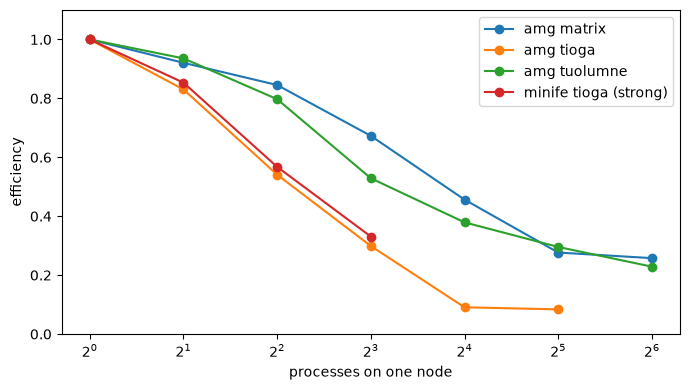

In [5]:
fig, ax = plt.subplots(figsize=(7, 4))
for name, e in curves.items():
    ax.plot(e.index, e.values, marker="o", label=name)
ax.set_xscale("log", base=2)
ax.set_ylim(0, 1.1)
ax.set_xlabel("processes on one node")
ax.set_ylabel("efficiency")
ax.legend()
fig.tight_layout()
fig.savefig("../figures/scaling-efficiency.png", dpi=120)
plt.show()

At 16 processes amg keeps 0.46 of its efficiency on matrix and 0.38 on tuolumne, and tioga falls to 0.09, where MPI takes over.
minife on tioga runs 2.6 times faster on 8 processes than on one, an efficiency of about a third.

## What you built

You read the kind of scaling from the data and measured the efficiency of two applications on one node.

- Next: [Read the host counters of each run](12-host-counters.ipynb)